<a href="https://colab.research.google.com/github/zxokam/Linear-Regression-ML-model/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#importing numpy libabry
import numpy as np

**Linear Regression**

In [2]:
class Linear_Regression:

#initiating the parameters (learning rate & no. of iterations)
  def __init__(self, learning_rate, no_of_iterations):

    self.learning_rate = learning_rate
    self.no_of_iterations = no_of_iterations

  def fit(self, X, Y):

    # number of training examples & number of features

    self.m, self.n = X.shape #number of rows & colums

    # initiating the weight and bias

    self.w = np.zeros(self.n)
    self.b = 0
    self.X = X
    self.Y = Y

    #implementing Gradient Descent

    for i in range(self.no_of_iterations):
      self.update_weight()

  def update_weight(self):

    Y_prediction = self.predict(self.X)

    #calculate gradients

    dw = - (2 * (self.X.T).dot(self.Y - Y_prediction)) / self.m

    db = -2 * np.sum(self.Y - Y_prediction)/ self.m

    #updating the weights

    self.w = self.w - self.learning_rate * dw

    self.b = self.b - self.learning_rate * db

  def predict(self, X):

    return X.dot(self.w) + self.b



Using Linear Regression model for Prediction

In [1]:
#importing the dependencies
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

Data Pre-Processing

In [4]:
# loading the data from csv file to a pandas dataframe

salary_data = pd.read_csv('/content/salary_data.csv')

In [5]:
# printing the first 5 colums of the dataframe
salary_data.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [7]:
# the last 5 rows of the dataframe
salary_data.tail()

,YearsExperience,Salary
25,9.0,105582
26,9.5,116969
27,9.6,112635
28,10.3,122391
29,10.5,121872


In [8]:
# number of rows & colums in the dataframe
salary_data.shape

(30, 2)

In [9]:
# checking for missing values
salary_data.isnull().sum()

,0
YearsExperience,0
Salary,0


spliting the feature and target

In [10]:
X = salary_data.iloc[:,:-1].values
Y = salary_data.iloc[:,1].values

In [11]:
print(X)

[[ 1.1]
 [ 1.3]
 [ 1.5]
 [ 2. ]
 [ 2.2]
 [ 2.9]
 [ 3. ]
 [ 3.2]
 [ 3.2]
 [ 3.7]
 [ 3.9]
 [ 4. ]
 [ 4. ]
 [ 4.1]
 [ 4.5]
 [ 4.9]
 [ 5.1]
 [ 5.3]
 [ 5.9]
 [ 6. ]
 [ 6.8]
 [ 7.1]
 [ 7.9]
 [ 8.2]
 [ 8.7]
 [ 9. ]
 [ 9.5]
 [ 9.6]
 [10.3]
 [10.5]]


In [12]:
print(Y)

[ 39343  46205  37731  43525  39891  56642  60150  54445  64445  57189
  63218  55794  56957  57081  61111  67938  66029  83088  81363  93940
  91738  98273 101302 113812 109431 105582 116969 112635 122391 121872]


spliting the dataset into training & test data

In [13]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33, random_state =2)

Training the Linear Regression model

In [14]:
model = Linear_Regression(learning_rate = 0.02, no_of_iterations = 1000)

In [15]:
model.fit(X_train, Y_train)

In [17]:
# printing the parameter values ( weights & bias)

print('weight = ', model.w[0])
print('bias = ', model.b)

weight =  9514.400999035135
bias =  23697.406507136307


y = 9514(X) + 23697

Predict the salary value fro test data

In [18]:
test_data_prediction = model.predict(X_test)

In [19]:
print(test_data_prediction)

[ 36066.12780588  34163.24760607  66512.21100279  58900.69020357
  91249.65360029  80783.81250135 101715.49469922  52240.60950424
  42726.20850521  88395.33330058]


Visualizing the predicited values & actual values

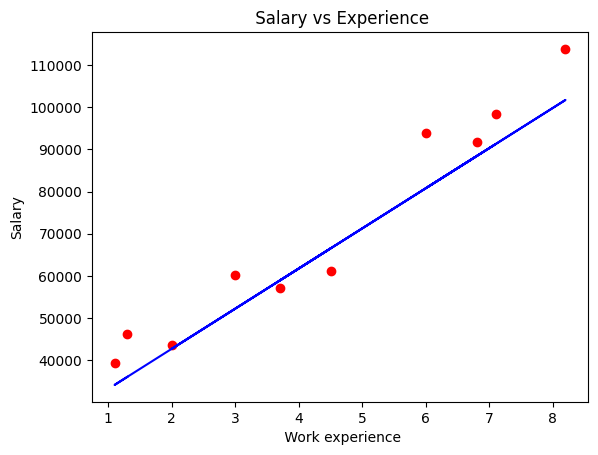

In [21]:
plt.scatter(X_test, Y_test, color = 'red')
plt.plot(X_test, test_data_prediction, color = 'blue')
plt.xlabel(' Work experience')
plt.ylabel('Salary')
plt.title(' Salary vs Experience')
plt.show()